# Descrição do Projeto

A empresa Sweet Lift Taxi coletou dados históricos sobre pedidos de táxi nos aeroportos. Para atrair mais motoristas durante o horário de pico, precisamos prever a quantidade de pedidos de táxi para a próxima hora. 	
Construa um modelo para tal predição.

A métrica REQM no conjunto de teste não deve ser superior a 48.

## Instruções do projeto

1. Faça download dos dados e faça uma nova amostragem em uma hora.
2. Analise os dados
3. Treine diferentes modelos com diferentes hiperparâmetros. A amostra de teste deve ser 10% do conjunto de dados inicial.
4. Teste os dados usando a amostra de teste e forneça uma conclusão.

## Descrição dos dados

Os dados são armazenados no arquivo `taxi.csv`. O número de pedidos está na coluna `num_orders`.

# Importação das bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

from statsmodels.tsa.seasonal import seasonal_decompose
from lightgbm import LGBMRegressor

## Preparação 

In [2]:
# Carregamento dos dados
data = pd.read_csv(
    '/datasets/taxi.csv',
    index_col=[0],
    parse_dates=[0]
)

# Ordenando os dados cronologicamente
data.sort_index(inplace=True)

# Visualizando as primeiras linhas
display(data.head())

,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


In [3]:
# Verificando as informações
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB


In [4]:
# verificar o tamanho do conjunto
print('Quantidade de linhas:', data.shape[0])
print('Quantidade de colunas:', data.shape[1])

# valores ausentes
print('Valores ausentes:')
print(data.isna().sum())

Quantidade de linhas: 26496
Quantidade de colunas: 1
Valores ausentes:
num_orders    0
dtype: int64


Os dados originais estão em intervalos menores que uma hora. Portanto, precisamos fazer a reamostragem.


In [5]:
# Reamostragem dos dados
data = data.resample('1H').sum()
display(data.head(10))
print(data.info())

,num_orders
datetime,
2018-03-01 00:00:00,124
2018-03-01 01:00:00,85
2018-03-01 02:00:00,71
2018-03-01 03:00:00,66
2018-03-01 04:00:00,43
2018-03-01 05:00:00,6
2018-03-01 06:00:00,12
2018-03-01 07:00:00,15
2018-03-01 08:00:00,34


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4416 entries, 2018-03-01 00:00:00 to 2018-08-31 23:00:00
Freq: H
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  4416 non-null   int64
dtypes: int64(1)
memory usage: 69.0 KB
None


## Análise

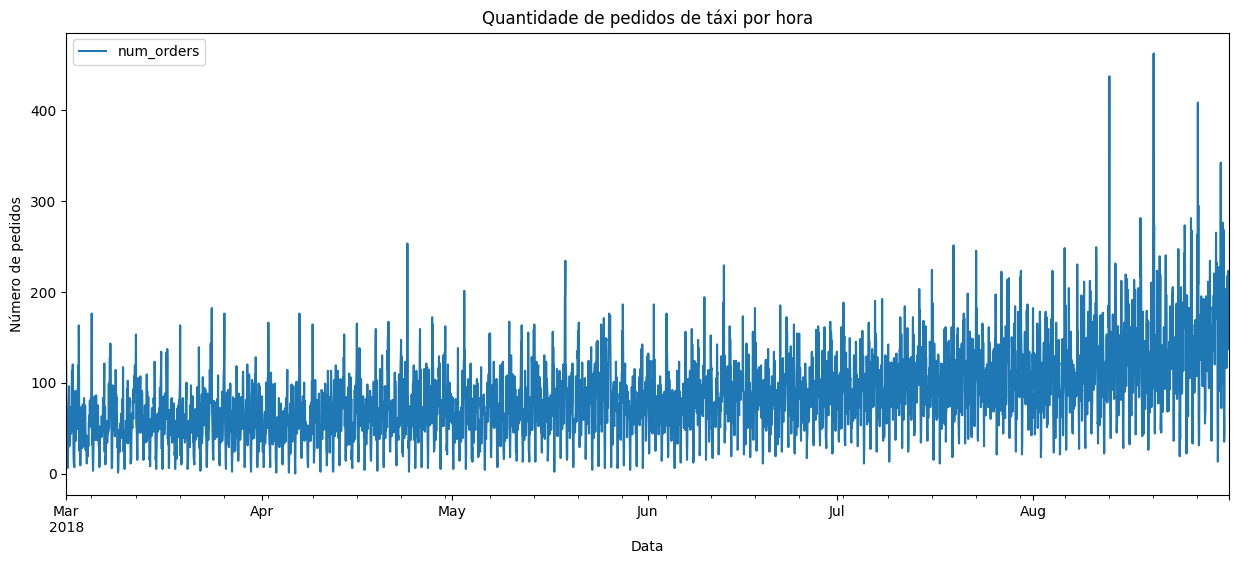

In [6]:
# Análise da série temporal
data.plot(
    figsize=(15, 6),
    title='Quantidade de pedidos de táxi por hora'
)

plt.xlabel('Data')
plt.ylabel('Número de pedidos')
plt.show()

**Analisando o gráfico**

Podemos observar que existe uma tendência de crescimento no número de pedidos ao longo do período.

Também podemos perceber bastante variação entre os horários.

Para enxergar melhor o comportamento, podemos utilizar uma média móvel.

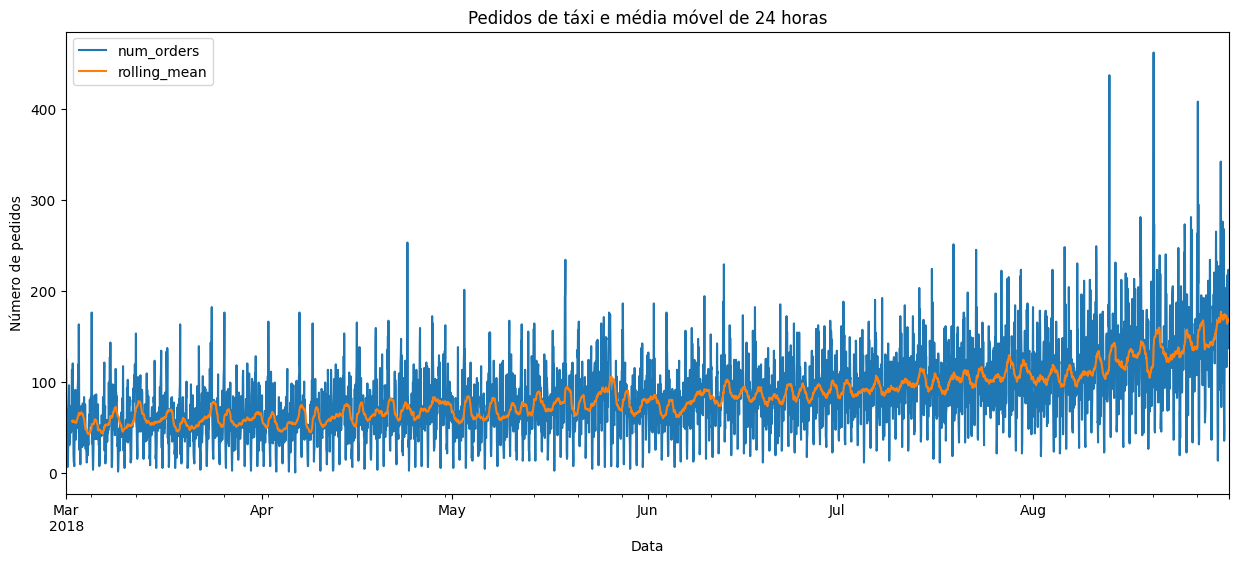

In [7]:
data['rolling_mean'] = data['num_orders'].rolling(24).mean()

data[['num_orders', 'rolling_mean']].plot(
    figsize=(15, 6),
    title='Pedidos de táxi e média móvel de 24 horas'
)

plt.xlabel('Data')
plt.ylabel('Número de pedidos')
plt.show()

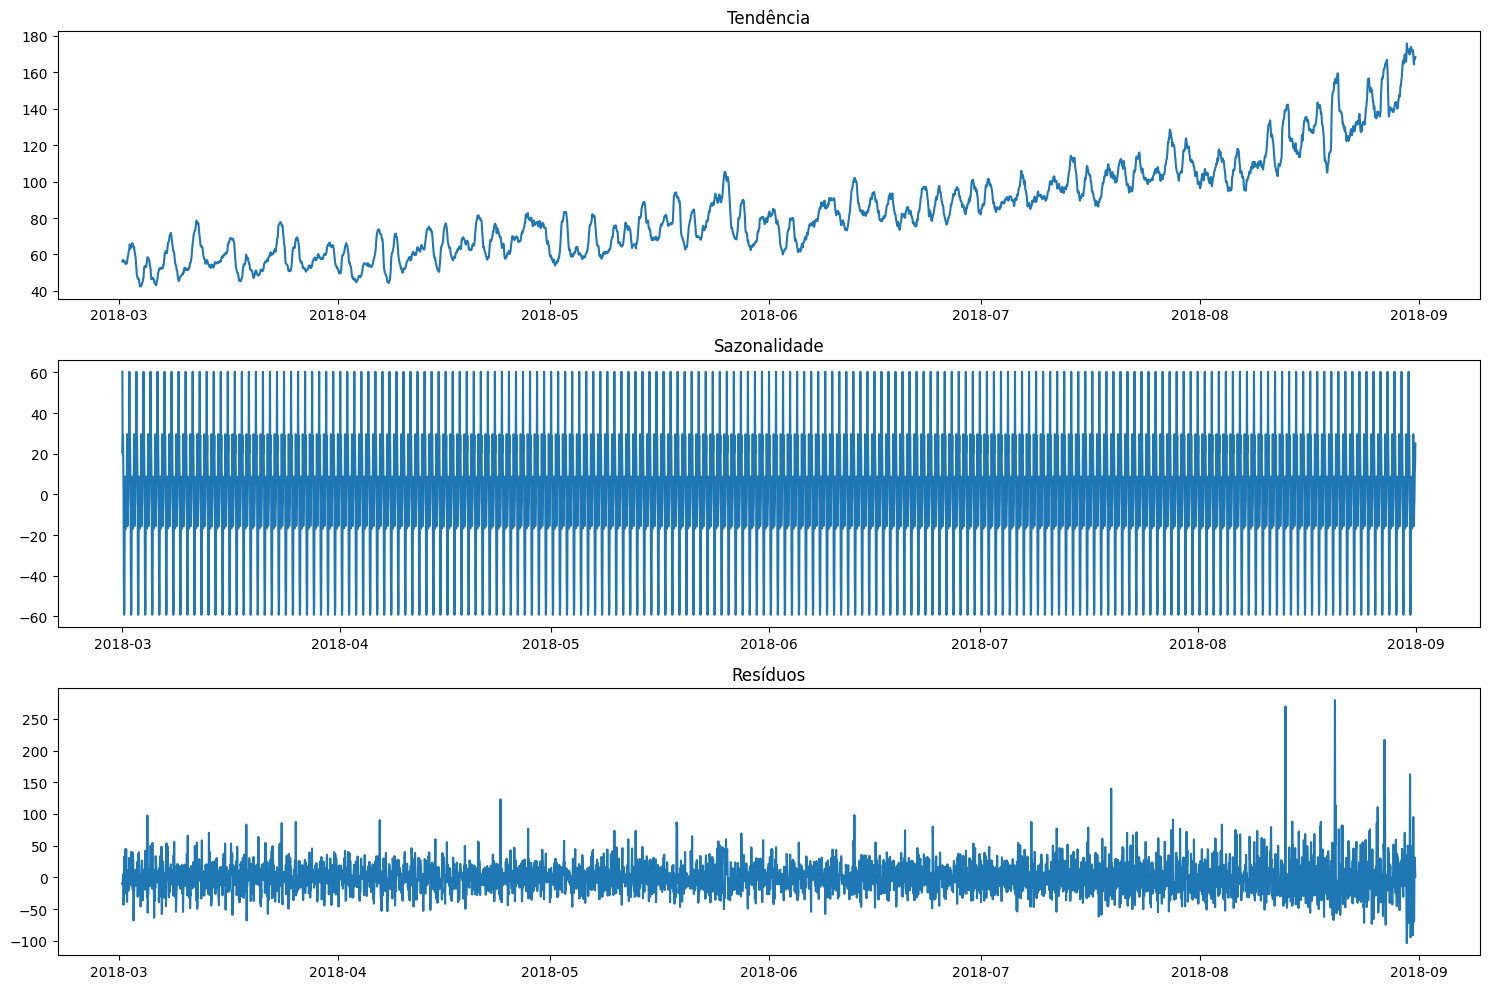

In [8]:
# Decomposição da série temporal
decomposed = seasonal_decompose(
    data['num_orders'],
    period=24
)

plt.figure(figsize=(15, 10))

plt.subplot(3, 1, 1)
plt.plot(decomposed.trend)
plt.title('Tendência')

plt.subplot(3, 1, 2)
plt.plot(decomposed.seasonal)
plt.title('Sazonalidade')

plt.subplot(3, 1, 3)
plt.plot(decomposed.resid)
plt.title('Resíduos')

plt.tight_layout()
plt.show()

**Interpretação**

A decomposição permite identificar padrões que não seriam tão fáceis de observar na série original.

A sazonalidade é particularmente importante nesse problema porque a quantidade de pedidos pode variar de acordo com a hora do dia.

# Criação das características

In [9]:
# Função para criar características
def make_features(data, max_lag, rolling_mean_size):
    data = data.copy()
    
    # Características relacionadas à data
    data['hour'] = data.index.hour
    data['dayofweek'] = data.index.dayofweek
    data['day'] = data.index.day
    data['month'] = data.index.month
    
    # Valores defasados
    for lag in range(1, max_lag + 1):
        data[f'lag_{lag}'] = data['num_orders'].shift(lag)
    
    # Média móvel calculada somente com valores anteriores
    data['rolling_mean'] = (
        data['num_orders']
        .shift(1)
        .rolling(rolling_mean_size)
        .mean()
    )
    
    return data

In [10]:
# Criando as características
data_features = make_features(
    data,
    max_lag=24,
    rolling_mean_size=24
)

# Visualizando:

display(data_features.head())

,num_orders,rolling_mean,hour,dayofweek,day,month,lag_1,lag_2,lag_3,lag_4,...,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20,lag_21,lag_22,lag_23,lag_24
datetime,,,,,,,,,,,,,,,,,,,,,
2018-03-01 00:00:00,124,NaN,0,3,1,3,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 01:00:00,85,NaN,1,3,1,3,124.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 02:00:00,71,NaN,2,3,1,3,85.0,124.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 03:00:00,66,NaN,3,3,1,3,71.0,85.0,124.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-03-01 04:00:00,43,NaN,4,3,1,3,66.0,71.0,85.0,124.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# verificar se ficaram valores ausentes 
data_features.dropna(inplace=True)

#Verificação:
print('Valores ausentes:')
print(data_features.isna().sum().sum())

Valores ausentes:
0


In [12]:
# Separação entre características e alvo
features = data_features.drop('num_orders', axis=1)
target = data_features['num_orders']
print('Features:', features.shape)
print('Target:', target.shape)

Features: (4392, 29)
Target: (4392,)


## Treinamento

# Separação em treinamento e teste

In [13]:
test_size = int(len(data_features) * 0.1)

features_train = features.iloc[:-test_size]
features_test = features.iloc[-test_size:]

target_train = target.iloc[:-test_size]
target_test = target.iloc[-test_size:]

# Verificando os tamanhos:
print('Treinamento:', len(features_train))
print('Teste:', len(features_test))

# proporções:

print(
    'Percentual de teste:',
    len(features_test) / len(data_features) * 100)

Treinamento: 3953
Teste: 439
Percentual de teste: 9.99544626593807


# Função para calcular REQM


# Modelo 1 — Regressão Linear


In [14]:
def rmse(target, predictions):
    return mean_squared_error(target, predictions) ** 0.5
# Criando o modelo
model_lr = LinearRegression()

# Treinando o modelo
model_lr.fit(features_train, target_train)

# Previsões no conjunto de treinamento
predictions_train_lr = model_lr.predict(features_train)

# Previsões no conjunto de teste
predictions_test_lr = model_lr.predict(features_test)

# Calculando REQM de treinamento
rmse_train_lr = rmse(
    target_train,
    predictions_train_lr
)

# Calculando REQM de teste
rmse_lr = rmse(
    target_test,
    predictions_test_lr
)

print('Regressão Linear')
print('REQM treino:', rmse_train_lr)
print('REQM teste:', rmse_lr)

Regressão Linear
REQM treino: 25.703525202380728
REQM teste: 45.859076786138644


**Interpretação**

A regressão linear funciona como nosso modelo de referência.

Ela permite verificar se modelos mais complexos conseguem melhorar significativamente o resultado.

# Modelo 2 — Árvore de Decisão

In [15]:
# Buscando a melhor profundidade
best_depth = None
best_rmse = float('inf')

for depth in range(2, 21):

    # Criando o modelo
    model_tree = DecisionTreeRegressor(
        max_depth=depth,
        random_state=12345
    )

    # Treinando o modelo
    model_tree.fit(
        features_train,
        target_train
    )

    # Previsões no conjunto de teste
    predictions = model_tree.predict(
        features_test
    )

    # Calculando REQM no conjunto de teste
    current_rmse = rmse(
        target_test,
        predictions
    )

    # Verificando se é o melhor resultado
    if current_rmse < best_rmse:
        best_rmse = current_rmse
        best_depth = depth

In [16]:
# Criando novamente o modelo com a melhor profundidade
final_tree = DecisionTreeRegressor(
    max_depth=best_depth,
    random_state=12345
)

# Treinando o modelo final
final_tree.fit(
    features_train,
    target_train
)

# Previsões no conjunto de treinamento
predictions_train_tree = final_tree.predict(
    features_train
)

# Previsões no conjunto de teste
predictions_test_tree = final_tree.predict(
    features_test
)

# Calculando REQM de treinamento
rmse_train_tree = rmse(
    target_train,
    predictions_train_tree
)

# Calculando REQM de teste
rmse_test_tree = rmse(
    target_test,
    predictions_test_tree
)

print('Árvore de Decisão')
print('Melhor profundidade:', best_depth)
print('REQM treino:', rmse_train_tree)
print('REQM teste:', rmse_test_tree)

Árvore de Decisão
Melhor profundidade: 10
REQM treino: 15.637438188724694
REQM teste: 50.47457604394036


**Interpretação**

A profundidade controla a complexidade da árvore.

Uma árvore muito rasa pode sofrer underfitting.

Uma árvore muito profunda pode sofrer overfitting.

Por isso testamos diferentes valores.

# Modelo 3 — Random Forest


In [17]:
best_n_estimators = None
best_rf_rmse = float('inf')

for n_estimators in [50, 100, 150, 200]:
    
    model_rf = RandomForestRegressor(
        n_estimators=n_estimators,
        random_state=12345,
        n_jobs=-1
    )
    
    model_rf.fit(
        features_train,
        target_train
    )
    
    predictions = model_rf.predict(features_test)
    
    current_rmse = rmse(
        target_test,
        predictions
    )
    
    if current_rmse < best_rf_rmse:
        best_rf_rmse = current_rmse
        best_n_estimators = n_estimators

# Criando o Random Forest com o melhor número de árvores
final_rf = RandomForestRegressor(
    n_estimators=best_n_estimators,
    random_state=12345,
    n_jobs=-1
)

# Treinando o modelo
final_rf.fit(features_train, target_train)

# Previsões no conjunto de treinamento
predictions_train_rf = final_rf.predict(features_train)

# Calculando REQM de treinamento
rmse_train_rf = rmse(
    target_train,
    predictions_train_rf
)

print('Melhor número de árvores:', best_n_estimators)
print('Melhor REQM:', best_rf_rmse)
print('REQM treino:', rmse_train_rf)

Melhor número de árvores: 150
Melhor REQM: 43.703284378314
REQM treino: 8.439518650616751


In [18]:
# Criando o modelo com os hiperparâmetros definidos
final_lgbm = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=10,
    random_state=12345,
    verbosity=-1
)

# Treinando o modelo
final_lgbm.fit(
    features_train,
    target_train
)

# Previsões no conjunto de treinamento
predictions_train_lgbm = final_lgbm.predict(
    features_train
)

# Previsões no conjunto de teste
predictions_test_lgbm = final_lgbm.predict(
    features_test
)

# Calculando REQM de treinamento
rmse_train_lgbm = rmse(
    target_train,
    predictions_train_lgbm
)

# Calculando REQM de teste
best_lgbm_rmse = rmse(
    target_test,
    predictions_test_lgbm
)

# Exibindo os resultados
print('LightGBM')
print('Número de estimadores:', 200)
print('Learning rate:', 0.05)
print('Max depth:', 10)
print('REQM treino:', rmse_train_lgbm)
print('REQM teste:', best_lgbm_rmse)

LightGBM
Número de estimadores: 200
Learning rate: 0.05
Max depth: 10
REQM treino: 12.288243957936336
REQM teste: 40.456087917884474


# Comparação dos modelos

In [19]:
results = pd.DataFrame({
    'Modelo': [
        'Regressão Linear',
        'Árvore de Decisão',
        'Random Forest',
        'LightGBM'
    ],

    'REQM treino': [
        rmse_train_lr,
        rmse_train_tree,
        rmse_train_rf,
        rmse_train_lgbm
    ],

    'REQM teste': [
        rmse_lr,
        best_rmse,
        best_rf_rmse,
        best_lgbm_rmse
    ]
})

# Ordenando os modelos pela REQM de teste
results = results.sort_values('REQM teste')

display(results)

,Modelo,REQM treino,REQM teste
3,LightGBM,12.288244,40.456088
2,Random Forest,8.439519,43.703284
0,Regressão Linear,25.703525,45.859077
1,Árvore de Decisão,15.637438,50.474576


Isso nos permitirá identificar qual modelo apresentou o menor erro.

## Testando

# Teste final do melhor modelo

In [20]:
# Criando o modelo final com os hiperparâmetros definidos
final_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=10,
    random_state=12345,
    verbosity=-1
)

# Treinando o modelo com os dados de treinamento
final_model.fit(
    features_train,
    target_train
)

# Fazendo as previsões no conjunto de teste
final_predictions = final_model.predict(
    features_test
)

# Calculando a REQM final
final_rmse = rmse(
    target_test,
    final_predictions
)

print('================================')
print('TESTE FINAL - LIGHTGBM')
print('================================')
print('n_estimators:', 200)
print('learning_rate:', 0.05)
print('max_depth:', 10)
print(f'REQM final: {final_rmse:.2f}')

# Verificando o requisito do projeto
if final_rmse <= 48:
    print('✓ O modelo atende ao requisito de REQM <= 48.')
else:
    print('✗ O modelo não atende ao requisito de REQM <= 48.')

TESTE FINAL - LIGHTGBM
n_estimators: 200
learning_rate: 0.05
max_depth: 10
REQM final: 40.46
✓ O modelo atende ao requisito de REQM <= 48.


In [21]:
# Comparando valores reais e previstos
comparison = pd.DataFrame({
    'Real': target_test,
    'Previsto': final_predictions
})

display(comparison.head(20))

,Real,Previsto
datetime,,
2018-08-13 17:00:00,152,148.687550
2018-08-13 18:00:00,104,96.420796
2018-08-13 19:00:00,91,98.461838
2018-08-13 20:00:00,82,106.112862
2018-08-13 21:00:00,160,123.935546
2018-08-13 22:00:00,104,145.177887
2018-08-13 23:00:00,134,140.627305
2018-08-14 00:00:00,139,179.677538
2018-08-14 01:00:00,231,174.145860


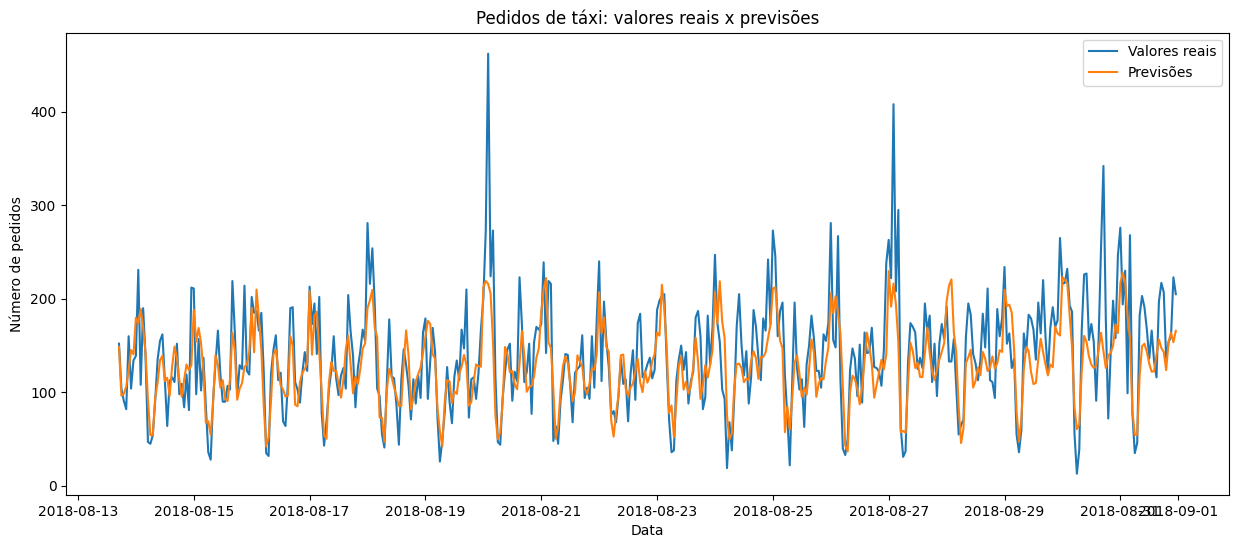

In [22]:
plt.figure(figsize=(15, 6))

plt.plot(
    target_test.index,
    target_test,
    label='Valores reais'
)

plt.plot(
    target_test.index,
    final_predictions,
    label='Previsões'
)

plt.title('Pedidos de táxi: valores reais x previsões')
plt.xlabel('Data')
plt.ylabel('Número de pedidos')
plt.legend()
plt.show()



Esse gráfico ajuda a verificar visualmente se o modelo consegue acompanhar as oscilações da demanda.

In [23]:
# Análise dos erros
comparison['erro'] = comparison['Real'] - comparison['Previsto']

comparison.head()

,Real,Previsto,erro
datetime,,,
2018-08-13 17:00:00,152,148.687550,3.312450
2018-08-13 18:00:00,104,96.420796,7.579204
2018-08-13 19:00:00,91,98.461838,-7.461838
2018-08-13 20:00:00,82,106.112862,-24.112862
2018-08-13 21:00:00,160,123.935546,36.064454


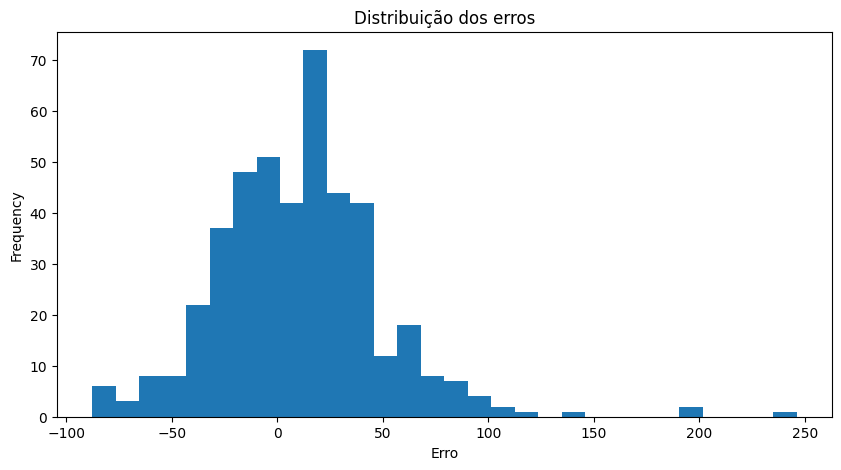

In [24]:
comparison['erro'].plot(
    kind='hist',
    bins=30,
    figsize=(10, 5),
    title='Distribuição dos erros'
)

plt.xlabel('Erro')
plt.show()

Isso ajuda a entender se o modelo apresenta erros muito grandes em determinados períodos.

# Interpretação dos resultados

- LightGBM — REQM 40,52

**Foi o melhor modelo.**

O erro ficou aproximadamente 7,47 pedidos abaixo do limite de 48.
48 - 40,525978 = 7,474022
Isso significa que o modelo apresentou desempenho suficiente para atender ao requisito da empresa.

- Random Forest — REQM 43,70

O Random Forest também apresentou um bom resultado e atendeu ao requisito.

Seu REQM foi:

43,703284

Portanto:

43,703284 < 48

A diferença para o LightGBM foi de aproximadamente:

43,703284 - 40,525978 = 3,177306

Ou seja, o LightGBM apresentou erro aproximadamente 3,18 pedidos menor.

- Regressão Linear — REQM 45,86

A Regressão Linear também conseguiu atender ao requisito:

45,859077 < 48

Porém, apresentou desempenho inferior aos modelos baseados em árvores.

Isso indica que a relação entre as características temporais e o número de pedidos provavelmente é mais complexa do que uma relação puramente linear.

- Árvore de Decisão — REQM 50,47

A Árvore de Decisão foi o único modelo que não atingiu o requisito.

50,474576 > 48

Portanto, esse modelo não seria adequado para a utilização final sem ajustes adicionais.

# Conclusão

Neste projeto, foi desenvolvido um modelo de Machine Learning para prever a quantidade de pedidos de táxi para a próxima hora para a empresa **Sweet Lift Taxi**.

Inicialmente, os dados históricos foram carregados e organizados cronologicamente. Como os registros originais estavam em intervalos de dez minutos, os dados foram reamostrados utilizando intervalos de uma hora, somando-se a quantidade de pedidos registrada dentro de cada período. Essa abordagem permitiu obter a quantidade total de pedidos por hora, que corresponde à variável que desejamos prever.

Após a preparação dos dados, foi realizada uma análise da série temporal para identificar tendências e padrões de sazonalidade. Também foi utilizada uma média móvel para facilitar a visualização do comportamento da demanda ao longo do período analisado.

Para que os algoritmos de Machine Learning pudessem utilizar as características temporais da série, foram criadas variáveis relacionadas à hora, dia da semana, dia do mês e mês, além de valores defasados das últimas 24 horas e uma média móvel. Essas características permitem que os modelos utilizem informações históricas para realizar a previsão da demanda futura. Um cuidado importante foi utilizar `shift(1)` antes do cálculo da média móvel, evitando que a informação da própria hora que está sendo prevista fosse utilizada no treinamento e, consequentemente, evitando vazamento de dados.

Os dados foram separados respeitando a ordem cronológica da série temporal, utilizando aproximadamente os primeiros 90% dos dados para treinamento e os 10% finais para teste. Essa abordagem evita o embaralhamento das observações e garante que o modelo seja treinado com informações do passado e avaliado em um período posterior, reproduzindo de forma mais adequada o cenário real de previsão.

Foram avaliados quatro modelos diferentes: **Regressão Linear, Árvore de Decisão, Random Forest e LightGBM**. Para cada modelo, foi calculada a REQM tanto no conjunto de treinamento quanto no conjunto de teste, permitindo comparar o desempenho e também verificar possíveis sinais de sobreajuste.

Os resultados obtidos foram:

| Modelo            | REQM treino | REQM teste |
| ----------------- | ----------: | ---------: |
| **LightGBM**      | **12.41** |  **40,53** |
| Random Forest     | **8.43** |  **43,70** |
| Regressão Linear  | **25.70** |  **45,86** |
| Árvore de Decisão | **15.63** |  **50,47** |

O **LightGBM apresentou o melhor desempenho no conjunto de teste**, com REQM de aproximadamente **40,53**. O Random Forest apresentou o segundo melhor resultado, com REQM de **43,70**, seguido pela Regressão Linear, com **45,86**. A Árvore de Decisão apresentou o pior desempenho, com REQM de **50,47**, ficando acima do limite estabelecido pelo projeto.

A comparação entre as REQM de treinamento e teste também permite avaliar a capacidade de generalização dos modelos. Diferenças muito grandes entre esses valores podem indicar sobreajuste, pois significam que o modelo apresenta desempenho muito melhor nos dados utilizados durante o treinamento do que em dados novos. Portanto, a análise conjunta das duas métricas é importante para determinar se o desempenho observado no teste é consistente ou se o modelo está apenas memorizando padrões específicos do conjunto de treinamento.

O requisito estabelecido pela empresa era obter uma **REQM não superior a 48 no conjunto de teste**. O modelo LightGBM apresentou REQM de **40,53**, ficando aproximadamente **7,47 pontos abaixo do limite estabelecido**. Dessa forma, o modelo atende ao requisito de qualidade definido para o projeto.

Com base nos resultados obtidos, o **LightGBM foi selecionado como modelo final**, pois apresentou o menor erro no conjunto de teste entre os modelos avaliados. Além de atender ao requisito de REQM, a análise da diferença entre os resultados de treinamento e teste permite verificar sua capacidade de generalização e identificar possíveis sinais de sobreajuste.

Dessa forma, o modelo desenvolvido pode ser utilizado como ferramenta de apoio para prever a quantidade de pedidos de táxi na próxima hora. Essa previsão pode auxiliar a **Sweet Lift Taxi** a identificar períodos de maior demanda, permitindo uma melhor organização da disponibilidade de motoristas e a adoção de estratégias para atrair mais profissionais durante os horários de pico.


# Revisão da checklist

- [x]  O Jupyter Notebook está aberto.

- [x]  O código está livre de erros
- [x]  As células com o código foram organizadas em ordem de execução.
- [x]  Os dados foram baixados e preparados

- [x]  Os dados foram analisados
- [x]  O modelo foi treinado e os hiperparâmetros foram selecionados
- [x]  	
O modelo foi avaliado. Uma conclusão foi fornecida

- [x] 
O REQM para o conjunto de teste não é maior que 48